# Hotel Booking Cancellations: Logistic Regression 

**Goal:** predict whether a hotel booking will be **cancelled** (`is_canceled = 1`) or not (`0`).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve,
    precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, brier_score_loss,
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

In [4]:
df_raw = pd.read_csv(r"C:\Hotel_booking_ML_project\Data\hotel_bookings.csv") 
print("Shape (rows, columns):", df_raw.shape) 
df_raw.head()  

Shape (rows, columns): (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
print("Share of cancelled bookings:", round(df_raw["is_canceled"].mean(), 3))
print("Exact duplicate rows:", df_raw.duplicated().sum(), f"({df_raw.duplicated().mean():.1%})")

#exploring data , duplicates, class balance(0.37), missing values 
missing = df_raw.isna().mean().sort_values(ascending=False)
print("\nColumns with missing values (share of rows):")
print(missing[missing > 0].round(3))

Share of cancelled bookings: 0.37
Exact duplicate rows: 31994 (26.8%)

Columns with missing values (share of rows):
company     0.943
agent       0.137
country     0.004
children    0.000
dtype: float64


### Which features seem to matter? (cancellation rate by group)



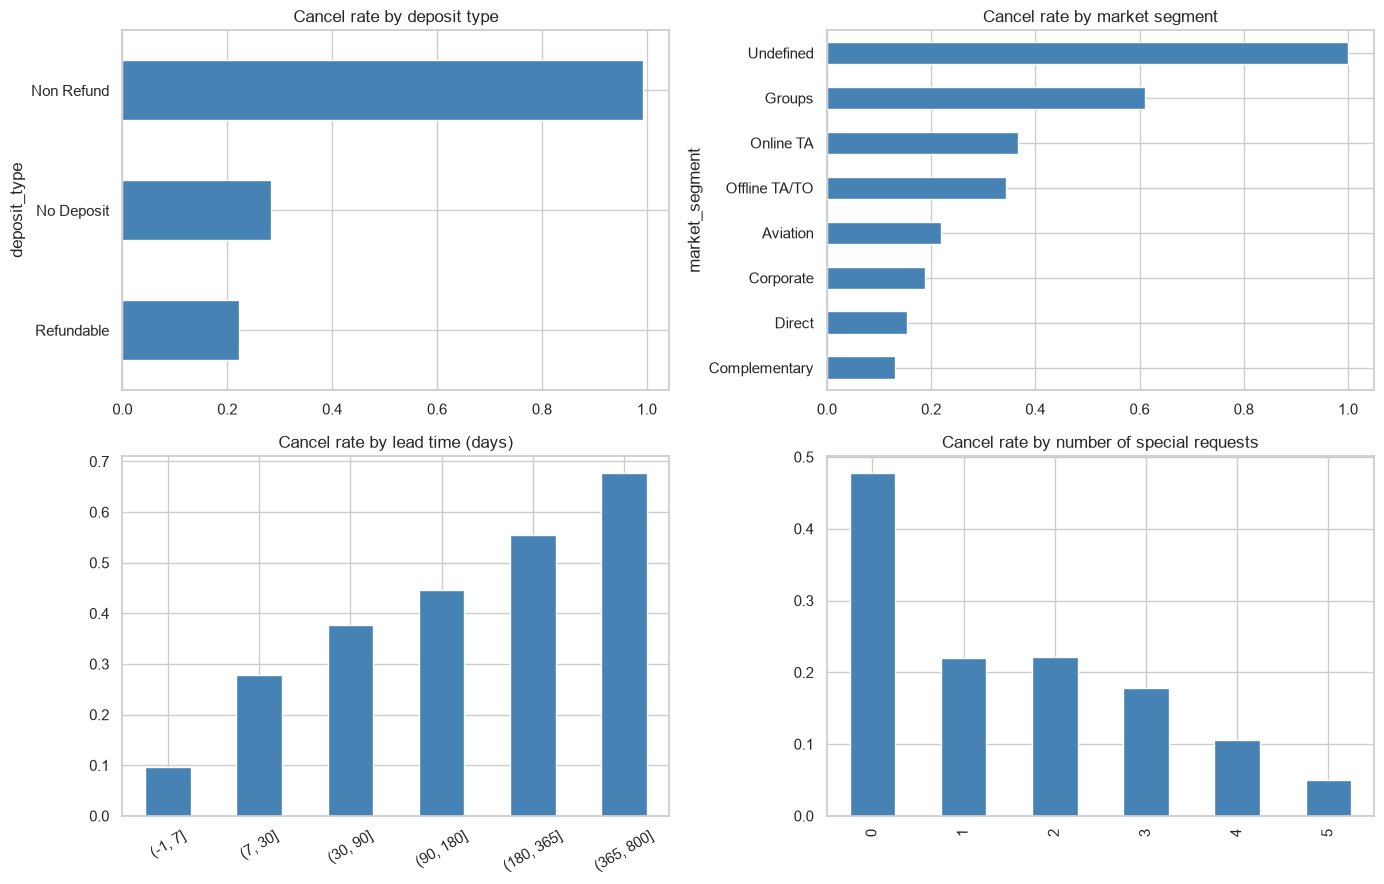

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) deposit type
df_raw.groupby("deposit_type")["is_canceled"].mean().sort_values().plot.barh(ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Cancel rate by deposit type")

# 2) market segment
df_raw.groupby("market_segment")["is_canceled"].mean().sort_values().plot.barh(ax=axes[0, 1], color="steelblue")
axes[0, 1].set_title("Cancel rate by market segment")

# 3) lead time (days between booking and arrival), grouped into bins
bins = pd.cut(df_raw["lead_time"], [-1, 7, 30, 90, 180, 365, 800])
df_raw.groupby(bins, observed=True)["is_canceled"].mean().plot.bar(ax=axes[1, 0], color="steelblue")
axes[1, 0].set_title("Cancel rate by lead time (days)")
axes[1, 0].tick_params(axis="x", rotation=30)

# 4) special requests
df_raw.groupby("total_of_special_requests")["is_canceled"].mean().plot.bar(ax=axes[1, 1], color="steelblue")
axes[1, 1].set_title("Cancel rate by number of special requests")

for ax in axes.ravel():
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

the longer the lead time, the higher the cancel rate (and the curve is not a straight line, which is why we add
a spline later). More special requests means fewer cancellations. Bookings with the `Non Refund` deposit type show a surprisingly *high* cancel rate.
That looks odd (you'd expect people not to cancel when they can't get money back) 

## 4. Clean the data and avoid data leakage

### Data Leakage 

* `reservation_status` ("Canceled", "Check-Out", "No-Show") is literally the outcome → **must be dropped** (you already did this).
* `reservation_status_date` is the date of that outcome → **must be dropped** (you already did this).
* `assigned_room_type` is the room given to the guest *at check-in*. A cancelled booking often never got a room assigned, so this column partly encodes the answer → **dropped** (new).

### Duplicates
If the same row appears twice and lands once in train and once in test, the model "recognises" it and the test score looks better than it really is.
We drop duplicates *before* splitting. If you want to keep them, set `DROP_DUPLICATES = False`.


In [ ]:
DROP_DUPLICATES = True

LEAKAGE_COLUMNS = ["reservation_status", "reservation_status_date", "assigned_room_type"]

def clean_and_engineer(raw: pd.DataFrame) -> pd.DataFrame:
    """Fixed, rule-based cleaning + feature engineering. Returns a new DataFrame."""
    d = raw.copy()

    if DROP_DUPLICATES:
        d = d.drop_duplicates()

    # remove leakage
    d = d.drop(columns=LEAKAGE_COLUMNS, errors="ignore")

    # fix obvious data problems 
    d["children"] = d["children"].fillna(0)          # 4 missing, assume none
    d["country"] = d["country"].fillna("Unknown")
    d["adr"] = d["adr"].clip(lower=0, upper=1000)    # 1 negative price, 1 absurd 5400 outlier

    # agent / company are ID codes, not quantities -> treat as categories / flags
    d["has_company"] = d["company"].notna().astype(int)
    d["agent"] = d["agent"].apply(lambda v: "no_agent" if pd.isna(v) else f"agent_{int(v)}")
    d = d.drop(columns=["company"])

    #  new, more informative features 
    d["total_nights"] = d["stays_in_weekend_nights"] + d["stays_in_week_nights"]
    d["weekend_share"] = np.where(d["total_nights"] > 0, d["stays_in_weekend_nights"] / d["total_nights"].replace(0, 1), 0)
    d["total_guests"] = d["adults"] + d["children"] + d["babies"]
    d["has_kids"] = ((d["children"] + d["babies"]) > 0).astype(int)
    d["has_parking"] = (d["required_car_parking_spaces"] > 0).astype(int)
    d["has_prev_cancellation"] = (d["previous_cancellations"] > 0).astype(int)
    d["has_booking_changes"] = (d["booking_changes"] > 0).astype(int)
    d["zero_night_stay"] = (d["total_nights"] == 0).astype(int)

    # columns replaced by the engineered ones above
    d = d.drop(columns=[
        "arrival_date_year",            # can't extrapolate a year trend to future bookings
        "arrival_date_week_number",     # redundant with arrival month
        "arrival_date_day_of_month",    # little signal                       
        "stays_in_weekend_nights", "stays_in_week_nights",
        "required_car_parking_spaces", 
    ])
    return d

df = clean_and_engineer(df_raw)
print("Rows before:", len(df_raw), "-> after cleaning:", len(df))
print("Cancel rate after cleaning:", round(df["is_canceled"].mean(), 3))
df.head()

Rows before: 119390 -> after cleaning: 87396
Cancel rate after cleaning: 0.275


,hotel,is_canceled,lead_time,arrival_date_month,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,total_of_special_requests,has_company,total_nights,weekend_share,total_guests,has_kids,has_parking,has_prev_cancellation,has_booking_changes,zero_night_stay
0,Resort Hotel,0,342,July,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,3,No Deposit,no_agent,0,Transient,0.0,0,0,0,0.0,2.0,0,0,0,1,1
1,Resort Hotel,0,737,July,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,4,No Deposit,no_agent,0,Transient,0.0,0,0,0,0.0,2.0,0,0,0,1,1
2,Resort Hotel,0,7,July,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,0,No Deposit,no_agent,0,Transient,75.0,0,0,1,0.0,1.0,0,0,0,0,0
3,Resort Hotel,0,13,July,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,0,No Deposit,agent_304,0,Transient,75.0,0,0,1,0.0,1.0,0,0,0,0,0
4,Resort Hotel,0,14,July,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,0,No Deposit,agent_240,0,Transient,98.0,1,0,2,0.0,2.0,0,0,0,0,0


## 5. Define features and split into train / test

We split the data **80% / 20%**:

* **Train set**: the model learns from this (and we do cross-validation).
* **Test set**: locked away until the very end, used **once** to report the final score.

We also group the columns by *how they should be preprocessed*. 

| Group | Meaning | Treatment |
|---|---|---|
| `spline_features` | non linear relationship | Spline (flexible curve) |
| `log_features` | Counts with many small values and a few very large ones, right tail skewed. | log(1+x) reduces skewness; standardisation puts values on a comparable scale. |
| `plain_features` | Ordinary numerical values | Impute missing values and standardise so features are comparable. |
| `flag_features` | Binary values (0 or 1) | Already numeric; no transformation needed.|
| `categorical_features` | text categories | One-hot encoding converts categories into numerical columns. |



In [ ]:
TARGET = "is_canceled"

spline_features = ["lead_time", "adr"]
log_features = ["days_in_waiting_list", "previous_cancellations", "previous_bookings_not_canceled",
                "booking_changes", "total_nights"]
plain_features = ["adults", "children", "babies", "total_guests", "weekend_share", "total_of_special_requests"]
flag_features = ["is_repeated_guest", "has_company", "has_kids", "has_parking",
                 "has_prev_cancellation", "has_booking_changes", "zero_night_stay"]
categorical_features = ["hotel", "arrival_date_month", "meal", "country", "market_segment",
                        "distribution_channel", "reserved_room_type", "deposit_type",                
                        "customer_type", "agent"]

all_features = spline_features + log_features + plain_features + flag_features + categorical_features
missing_cols = set(df.columns) - set(all_features) - {TARGET}
assert not missing_cols, f"Columns not assigned to a group: {missing_cols}"

X = df[all_features]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y # keeps the same class balance in train and test sets
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Cancel rate train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Train: (69916, 30) | Test: (17480, 30)
Cancel rate train / test: 0.275 / 0.275


## 6. Preprocessing pipeline

Everything below is *learned from the training data only* and then re-applied to new data. That is exactly why we use a `Pipeline`.

**Why these choices?**

* **Splines for `lead_time` and `adr`:** plain logistic regression assumes each extra day of lead time changes the log-odds by the *same* amount.
  Reality is curved (the first weeks matter a lot, very long lead times flatten out). A spline splits the number line into pieces and fits a smooth curve through
  them, so the *model stays linear and interpretable* but can bend.
* **`log(1 + x)`:** counts such as `days_in_waiting_list` have a few huge values. A log squashes them so they do not dominate.
* **`OneHotEncoder(min_frequency=100, handle_unknown="infrequent_if_exist")`:** `country` has ~170 values and `agent` ~330. Categories that appear fewer than
  100 times are merged into one "infrequent" bucket. That reduces noise/overfitting and also lets the model cope with categories it has never seen.
* **Imputers:** fill any remaining gaps (median for numbers, most frequent for categories) so the model never receives `NaN`.

In [9]:
spline_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("spline", SplineTransformer(n_knots=6, degree=3, knots="quantile", extrapolation="constant")),
])

log_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler()),
])

plain_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("spline", spline_transformer, spline_features),
        ("log", log_transformer, log_features),
        ("plain", plain_transformer, plain_features),
        ("flag", "passthrough", flag_features),
        ("cat", categorical_transformer, categorical_features),
    ],
    verbose_feature_names_out=True,
)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('spline', ...), ('log', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featur

## 7. Models

### How logistic regression works 
1. It computes a weighted sum of the features: `z = b0 + b1·x1 + b2·x2 + …` (this `z` is called the **log-odds**).
2. It squeezes `z` into a probability between 0 and 1 using the **sigmoid** function: `p = 1 / (1 + e^(-z))`.
3. If `p ≥ threshold` (default 0.5) we predict "cancelled".

The weights `b` are learned by minimising the log-loss. **Regularisation** (parameter `C`) stops the weights from getting extreme:
*small `C` = strong regularisation = simpler model*, *large `C` = weak regularisation*.

### We compare three models on the *same* cleaned data
1. **Baseline:** plain logistic regression, all numeric columns standardised, no splines (so it is like just on clean data).
2. **Improved logistic regression:** splines + log transforms + merged rare categories (our main model).
3. **gradient boosting:** A much more flexible non-linear model. 

In [ ]:
# 1) Baseline: no splines, no log transform, just scale numbers + one-hot encode categories
baseline_numeric = spline_features + log_features + plain_features
baseline_pre = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), baseline_numeric),
                        #imputer: Replaces missing numerical values with the median.
                        # scaler: Standardises numerical values (mean = 0, standard deviation = 1).
    ("flag", "passthrough", flag_features),#Keeps binary columns (0/1) unchanged.
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
                      #Fills missing categorical values with the most frequent category.
                      #Converts categories into numerical columns using One-Hot Encoding.
                      # handle_unknown="ignore" prevents errors when new categories appear in test data
                      
])
baseline_model = Pipeline([
    ("preprocessor", baseline_pre),
    ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

# 2) Improved logistic regression 
improved_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(C=1.0, max_iter=3000, random_state=RANDOM_STATE)),
])

# 3) Reference model 
gradient_boosting = ColumnTransformer([
    ("num", "passthrough", spline_features + log_features + plain_features + flag_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False))]),
     categorical_features),
     #For categorical features:
     # - Replaces missing values with the most frequent category.
     # - Groups rare categories (fewer than 100 occurrences) into an infrequent category.
     # - Converts categories into numerical columns.
])
reference_model = Pipeline([
    ("preprocessor", gradient_boosting),
    ("classifier", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
])

### Cross-validation 

**Cross-validation (CV)** splits the training data into 5 folds. The model is trained on 4 and scored on the 5th, rotating 5 times.
You get 5 scores instead of 1, so we can see both the *average* and how *stable* the model is.

We use **ROC-AUC** as the score: it measures how well the model *ranks* cancelled bookings above non-cancelled ones
(0.5 = coin flip, 1.0 = perfect), independent of any threshold.

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = {}
for name, model in [("Baseline LR", baseline_model),
                    ("Improved LR", improved_model),
                    ("Reference: Gradient Boosting", reference_model)]:
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    results[name] = scores
    print(f"{name:32s} ROC-AUC: {scores.mean():.4f}  (+/- {scores.std():.4f})")

Baseline LR                      ROC-AUC: 0.8592  (+/- 0.0018)
Improved LR                      ROC-AUC: 0.8733  (+/- 0.0032)
Reference: Gradient Boosting     ROC-AUC: 0.9044  (+/- 0.0032)


In [24]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = ["roc_auc", "precision", "recall"]

results = {}

for name, model in [
    ("Baseline LR", baseline_model),
    ("Improved LR", improved_model),
    ("Reference: Gradient Boosting", reference_model)
]:
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results[name] = scores

    print(f"\n{name}")
    print(f"ROC-AUC:   {scores['test_roc_auc'].mean():.4f} (+/- {scores['test_roc_auc'].std():.4f})")
    print(f"Precision: {scores['test_precision'].mean():.4f} (+/- {scores['test_precision'].std():.4f})")
    print(f"Recall:    {scores['test_recall'].mean():.4f} (+/- {scores['test_recall'].std():.4f})")


Baseline LR
ROC-AUC:   0.8592 (+/- 0.0018)
Precision: 0.6904 (+/- 0.0062)
Recall:    0.5267 (+/- 0.0048)

Improved LR
ROC-AUC:   0.8733 (+/- 0.0032)
Precision: 0.7070 (+/- 0.0051)
Recall:    0.5767 (+/- 0.0058)

Reference: Gradient Boosting
ROC-AUC:   0.9044 (+/- 0.0032)
Precision: 0.7419 (+/- 0.0036)
Recall:    0.6405 (+/- 0.0065)


## 8. Hyperparameter tuning

A **hyperparameter** is a setting we choose *before* training (the model doesn't learn it). For logistic regression the important ones are:

* **`C`**: inverse regularisation strength: Controls how much the model is penalised for being too complex.
Small C → stronger penalty → simpler model.
Large C → weaker penalty → more complex model.

* **`class_weight`**: `None` treats all rows equally, `"balanced"`  the model is penalised more for incorrectly classifying cancelled bookings.


In [32]:
param_grid = {
    "classifier__C": [0.03, 0.1, 0.3, 1, 3, 10, 30, 100],
    "classifier__class_weight": [None, "balanced"],
}

grid = GridSearchCV(
    estimator=improved_model,
    param_grid=param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 4))
best_model = grid.best_estimator_      # stores the best pipleline (preprocessor + classifier) with the best hyperparameters found
#weak regularization , preferes complex models, class_weight=none, which means it does not adjust weights inversely proportional to class frequencies. This is useful when the classes are imbalanced, as it can help the model pay more attention to the minority class.

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters: {'classifier__C': 30, 'classifier__class_weight': None}
Best CV ROC-AUC: 0.8735


In [33]:
# See how the score changes with C (helps you judge if the choice is stable or on an edge)
cv_table = (pd.DataFrame(grid.cv_results_)[["param_classifier__C", "param_classifier__class_weight", "mean_test_score", "std_test_score"]]
            .rename(columns=lambda c: c.replace("param_classifier__", ""))
            .sort_values("mean_test_score", ascending=False))
cv_table.round(4)

,C,class_weight,mean_test_score,std_test_score
12,30.00,NaN,0.8735,0.0031
10,10.00,NaN,0.8735,0.0031
14,100.00,NaN,0.8735,0.0031
8,3.00,NaN,0.8735,0.0031
15,100.00,balanced,0.8735,0.0030
13,30.00,balanced,0.8735,0.0030
9,3.00,balanced,0.8734,0.0030
11,10.00,balanced,0.8734,0.0029
7,1.00,balanced,0.8734,0.0030
6,1.00,NaN,0.8733,0.0032


In [ ]:
# Predictions on training data
y_train_proba = best_model.predict_proba(X_train)[:, 1]

train_auc = roc_auc_score(y_train, y_train_proba)

print("Training ROC-AUC:", round(train_auc, 4))
print("CV ROC-AUC:", round(grid.best_score_, 4))
# minor overfitting but negligible, so we can use the model for predictions on the test set

Training ROC-AUC: 0.8751
CV ROC-AUC: 0.8735


## 9. Choosing the decision threshold (the right way)

The model outputs a **probability** . To get a yes/no answer we need a **threshold**.

* **False negative** (we say "will show up" but the guest cancels): an empty room that could have been resold.- potential sales lost
* **False positive** (we say "will cancel" but the guest comes): if we overbook based on this, an unhappy guest might be turned away.

1. Get **out-of-fold predictions** on the *training* set (`cross_val_predict`: each row is predicted by a model that never saw it).
2. Pick the threshold that maximises the **F1-score** on those predictions (F1 balances precision and recall).
3. Lock that threshold in and use it on the test set exactly once.


Chosen threshold: 0.345  (out-of-fold precision 0.619, recall 0.754, F1 0.680)


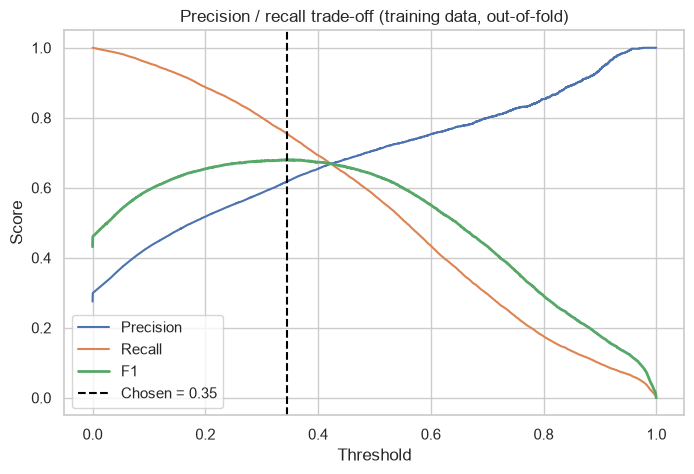

In [14]:
oof_prob = cross_val_predict(clone(best_model), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_prob)
f1_scores = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_idx = np.argmax(f1_scores)
BEST_THRESHOLD = float(thr[best_idx])

print(f"Chosen threshold: {BEST_THRESHOLD:.3f}  "
      f"(out-of-fold precision {prec[best_idx]:.3f}, recall {rec[best_idx]:.3f}, F1 {f1_scores[best_idx]:.3f})")

plt.figure(figsize=(8, 5))
plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.plot(thr, f1_scores, label="F1", linewidth=2)
plt.axvline(BEST_THRESHOLD, color="black", linestyle="--", label=f"Chosen = {BEST_THRESHOLD:.2f}")
plt.xlabel("Threshold"); plt.ylabel("Score"); plt.title("Precision / recall trade-off (training data, out-of-fold)")
plt.legend(); plt.show()

## 10. Final evaluation on the test set

Now, and only now, we touch the test set. We compare all models and show the improved logistic regression at the default 0.5 threshold and at our chosen one.

**Metrics explained**

* **Accuracy**: share of all predictions that were correct. Simple, but can hide problems when classes are imbalanced.
* **Precision**: of the bookings we flagged as "will cancel", how many really did?
* **Recall**: of all bookings that really cancelled, how many did we catch?
* **F1**: the balance of precision and recall.
* **ROC-AUC**: ranking quality across *all* thresholds.
* **PR-AUC (average precision)**: like ROC-AUC but focused on the cancelled class; more informative when that class is the minority.
* **Brier score**: how close the predicted probabilities are to reality (lower is better).

In [15]:
def summarise(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "Model": name,
        "Threshold": round(threshold, 3),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
    }

# Fit the other two on the full training set and score them on the test set
baseline_model.fit(X_train, y_train)
reference_model.fit(X_train, y_train)

prob_baseline  = baseline_model.predict_proba(X_test)[:, 1]
prob_best      = best_model.predict_proba(X_test)[:, 1]
prob_reference = reference_model.predict_proba(X_test)[:, 1]

summary = pd.DataFrame([
    summarise("Baseline LR (0.5)", y_test, prob_baseline, 0.5),
    summarise("Improved LR (0.5)", y_test, prob_best, 0.5),
    summarise("Improved LR (tuned threshold)", y_test, prob_best, BEST_THRESHOLD),
    summarise("Reference GB (0.5)", y_test, prob_reference, 0.5),
]).set_index("Model")
summary.round(3)

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier
Model,,,,,,,,
Baseline LR (0.5),0.500,0.803,0.685,0.527,0.596,0.859,0.703,0.132
Improved LR (0.5),0.500,0.819,0.706,0.582,0.638,0.873,0.723,0.125
Improved LR (tuned threshold),0.345,0.804,0.617,0.755,0.679,0.873,0.723,0.125
Reference GB (0.5),0.500,0.838,0.739,0.636,0.683,0.903,0.785,0.111


In [16]:
final_pred = (prob_best >= BEST_THRESHOLD).astype(int)
print(classification_report(y_test, final_pred, target_names=["Not cancelled", "Cancelled"]))

               precision    recall  f1-score   support

Not cancelled       0.90      0.82      0.86     12675
    Cancelled       0.62      0.76      0.68      4805

     accuracy                           0.80     17480
    macro avg       0.76      0.79      0.77     17480
 weighted avg       0.82      0.80      0.81     17480



### Confusion matrix

Rows = what really happened, columns = what the model predicted.

* top-left: correctly predicted *not cancelled*; bottom-right: correctly predicted *cancelled*
* top-right (**false positives**): predicted cancel, guest came
* bottom-left (**false negatives**): predicted stay, guest cancelled

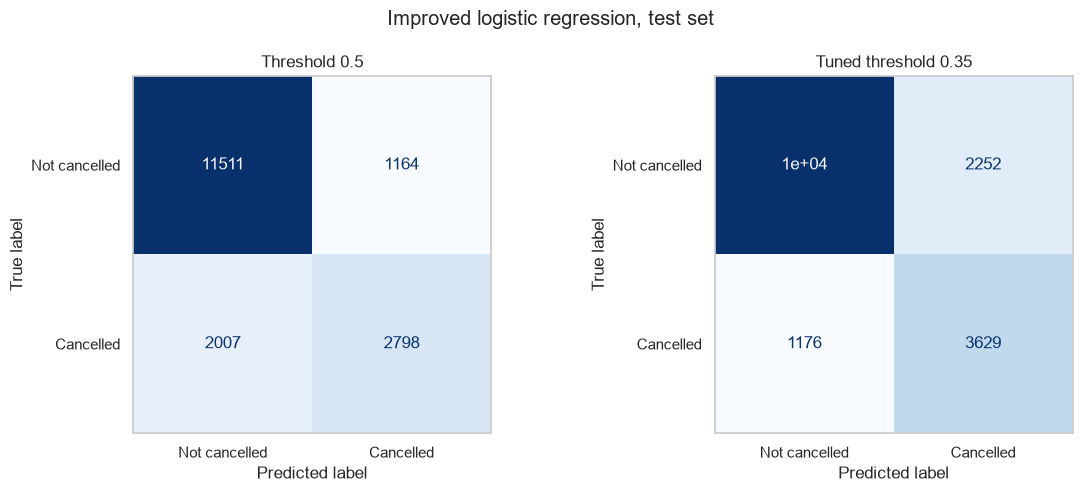

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, thr_, title in [(axes[0], 0.5, "Threshold 0.5"), (axes[1], BEST_THRESHOLD, f"Tuned threshold {BEST_THRESHOLD:.2f}")]:
    cm = confusion_matrix(y_test, (prob_best >= thr_).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Not cancelled", "Cancelled"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
    ax.grid(False)
plt.suptitle("Improved logistic regression, test set")
plt.tight_layout(); plt.show()

### ROC and Precision-Recall curves

* **ROC curve**: the closer to the top-left corner, the better; the diagonal is random guessing.
* **Precision-Recall curve**: shows the trade-off as you move the threshold. Higher and further right is better.

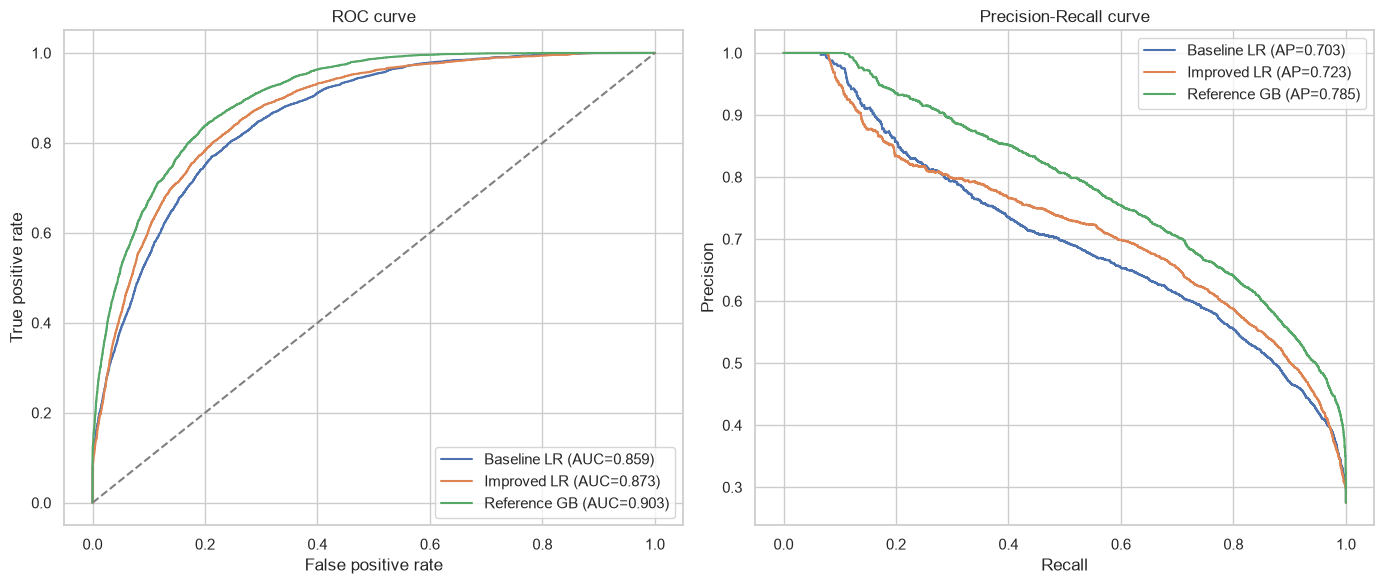

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for label, p in [("Baseline LR", prob_baseline), ("Improved LR", prob_best), ("Reference GB", prob_reference)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, label=f"{label} (AP={average_precision_score(y_test, p):.3f})")

axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()

### Calibration: can we trust the probabilities?

Points close to the diagonal mean the probabilities are trustworthy. It matters because we use these measures for decisions (e.g. how much to overbook) rather than only for yes/no labels.
Note: with `class_weight="balanced"` the probabilities are deliberately shifted upward, so the curve will sit **below** the diagonal. Since calibaration matters, we
choose the `class_weight=None` 

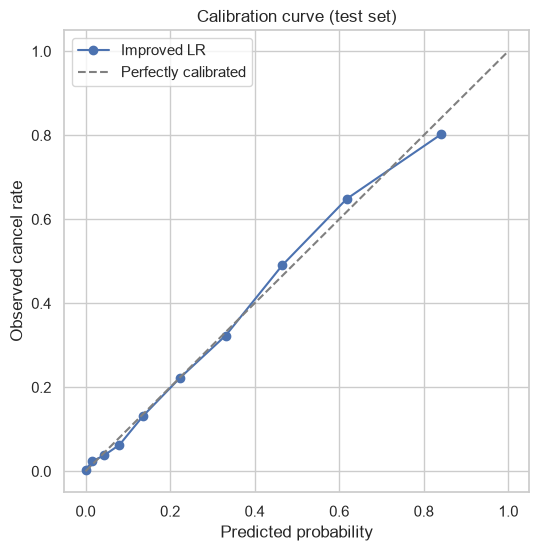

In [ ]:
frac_pos, mean_pred = calibration_curve(y_test, prob_best, n_bins=10, strategy="quantile")

plt.figure(figsize=(6, 6)) 
plt.plot(mean_pred, frac_pos, marker="o", label="Improved LR") 
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfectly calibrated") 
plt.xlabel("Predicted probability"); plt.ylabel("Observed cancel rate")    
plt.title("Calibration curve (test set)") 
plt.legend(); plt.show()     

## 11. Interpreting the model: what drives cancellations?

* A **coefficient** is the change in log-odds for a 1-unit increase in the feature (for standardised numbers, 1 unit = 1 standard deviation; for one-hot columns, "being in that category vs. not").
* **Odds ratio = e^coefficient.** An odds ratio of 2 means the odds of cancelling are doubled (holding everything else fixed); 0.5 means they are halved; 1 means no effect.



In [20]:
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
coefs = best_model.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({"Feature": feature_names, "Coefficient": coefs})
coef_df["Odds_Ratio"] = np.exp(coef_df["Coefficient"])
coef_df["Feature"] = (coef_df["Feature"]
                      .str.replace("cat__", "", regex=False).str.replace("flag__", "", regex=False)
                      .str.replace("log__", "", regex=False).str.replace("plain__", "", regex=False))

readable = coef_df[~coef_df["Feature"].str.startswith("spline__")].sort_values("Coefficient", ascending=False)

print("Top 15 features that INCREASE cancellation odds:")
display(readable.head(15).round(3))
print("Top 15 features that DECREASE cancellation odds:")
display(readable.tail(15).iloc[::-1].round(3))

Top 15 features that INCREASE cancellation odds:


,Feature,Coefficient,Odds_Ratio
31,has_prev_cancellation,3.725,41.467
109,reserved_room_type_infrequent_sklearn,3.119,22.614
142,agent_agent_240,2.059,7.841
53,country_AGO,2.003,7.408
100,distribution_channel_infrequent_sklearn,1.860,6.422
166,agent_agent_9,1.776,5.908
80,country_PRT,1.673,5.330
111,deposit_type_Non Refund,1.548,4.704
144,agent_agent_242,1.160,3.190
76,country_MAR,1.035,2.816


Top 15 features that DECREASE cancellation odds:


,Feature,Coefficient,Odds_Ratio
30,has_parking,-8.449,0.000
33,zero_night_stay,-1.839,0.159
110,deposit_type_No Deposit,-1.421,0.241
130,agent_agent_16,-1.297,0.273
131,agent_agent_168,-1.289,0.276
128,agent_agent_152,-1.264,0.283
32,has_booking_changes,-1.126,0.324
151,agent_agent_28,-1.103,0.332
120,agent_agent_115,-0.982,0.375
140,agent_agent_22,-0.972,0.378


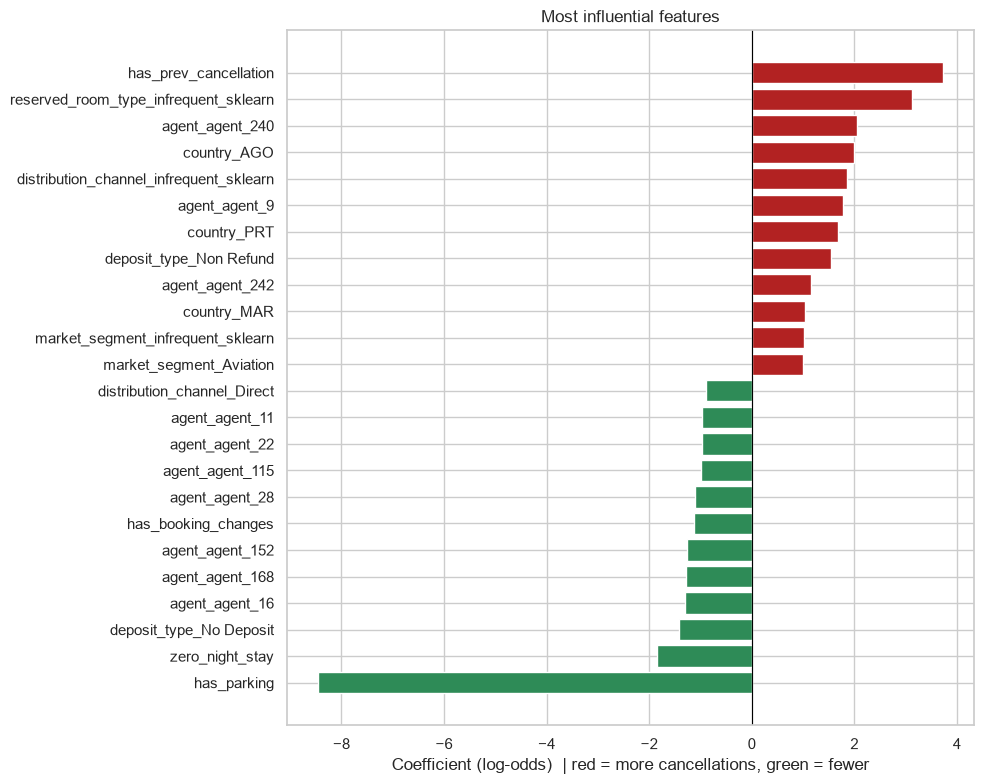

In [21]:
top = pd.concat([readable.head(12), readable.tail(12)])

plt.figure(figsize=(10, 8))
colors = ["firebrick" if c > 0 else "seagreen" for c in top["Coefficient"]]
plt.barh(top["Feature"], top["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.xlabel("Coefficient (log-odds)  | red = more cancellations, green = fewer")
plt.title("Most influential features")
plt.tight_layout(); plt.show()

### The lead-time and price curves (what the splines learned)

We take a "typical" booking and vary only `lead_time` (then `adr`), asking the model for the cancel probability. If the line were straight, splines would not be needed.

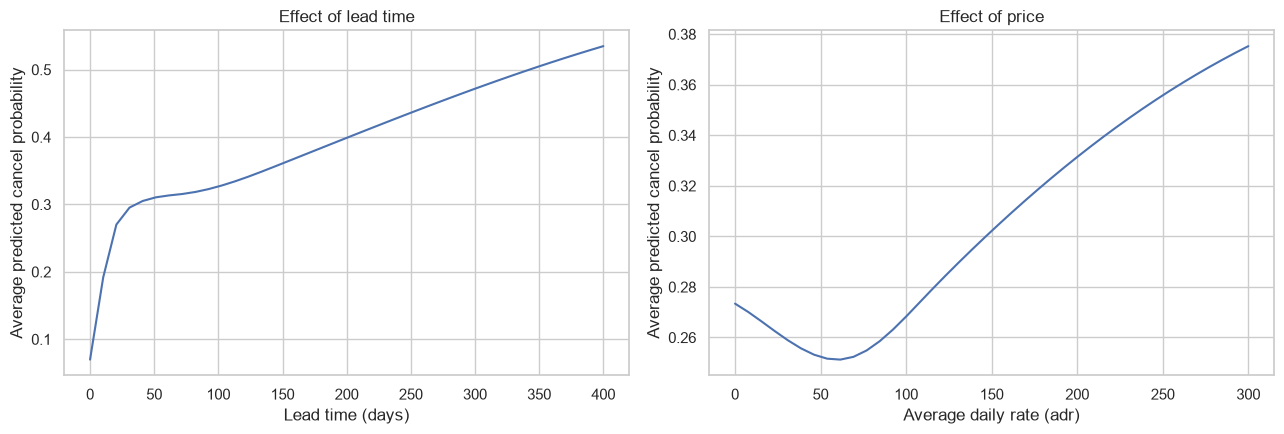

In [ ]:
def partial_curve(feature, grid_values):
    base = X_train.copy().sample(2000, random_state=RANDOM_STATE)
    out = []
    for v in grid_values:
        tmp = base.copy()
        tmp[feature] = v
        out.append(best_model.predict_proba(tmp)[:, 1].mean())
    return out

lead_grid = np.linspace(0, 400, 40)
adr_grid = np.linspace(0, 300, 40)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(lead_grid, partial_curve("lead_time", lead_grid))
axes[0].set(xlabel="Lead time (days)", ylabel="Average predicted cancel probability", title="Effect of lead time")
axes[1].plot(adr_grid, partial_curve("adr", adr_grid))
axes[1].set(xlabel="Average daily rate (adr)", ylabel="Average predicted cancel probability", title="Effect of price")
plt.tight_layout(); plt.show()


## 12. Saving the model

The whole pipeline (preprocessing + model) is saved in one file, so we can load it later and give it a raw booking row.
we also store `BEST_THRESHOLD` with it. the new data must be clean and preprocessed tho

In [38]:
joblib.dump({"model": best_model, "threshold": BEST_THRESHOLD, "features": all_features}, "hotel_cancellation_logreg.joblib")

# Example: score the first 10 test bookings
example = X_test.head(10)
probs = best_model.predict_proba(example)[:, 1]
pd.DataFrame({
    "cancel_probability": probs.round(3),
    "prediction": np.where(probs >= BEST_THRESHOLD, "Cancel", "Stay"),
    "actual": np.where(y_test.head(10) == 1, "Cancel", "Stay"),
})

,cancel_probability,prediction,actual
0,0.069,Stay,Stay
1,0.612,Cancel,Stay
2,0.586,Cancel,Stay
3,0.124,Stay,Cancel
4,0.341,Stay,Cancel
5,0.001,Stay,Stay
6,0.808,Cancel,Stay
7,0.598,Cancel,Cancel
8,0.904,Cancel,Cancel
9,0.071,Stay,Stay



Ideas
* Add an interaction term 
* Try a time-based split
* optimize the threshold for GB too 